## Customer Analytics

In [49]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Thiết lập thư mục và đọc dữ liệu
data_path = Path("data/raw/Dunnhumby/transaction_data.csv")
if not data_path.exists():
    data_path = Path("../data/raw/Dunnhumby/transaction_data.csv")

print(f"Đang đọc dữ liệu từ: {data_path}")
df_raw = pd.read_csv(data_path, usecols=["household_key", "BASKET_ID", "DAY", "SALES_VALUE"])
print(f"Tổng số dòng giao dịch thô: {len(df_raw):,}")

Đang đọc dữ liệu từ: ..\data\raw\Dunnhumby\transaction_data.csv
Tổng số dòng giao dịch thô: 2,595,732


In [50]:
# Lọc giao dịch hợp lệ (SALES_VALUE > 0) và trích xuất các ngày mua sắm duy nhất theo hộ gia đình
df_valid = (
    df_raw[df_raw["SALES_VALUE"] > 0][["household_key", "DAY"]]
    .drop_duplicates()
    .sort_values(["household_key", "DAY"])
)

# Tính khoảng cách số ngày giữa các lần ghé mua liên tiếp (Return Gap in Days)
df_valid["gap_days"] = df_valid.groupby("household_key")["DAY"].diff()
gaps = df_valid["gap_days"].dropna().astype(int)

print(f"Tổng số lượt quay lại mua sắm (Return events): {len(gaps):,}")
print(f"Số hộ gia đình phát sinh >= 2 lần mua: {df_valid['household_key'].nunique():,}")

Tổng số lượt quay lại mua sắm (Return events): 222,785
Số hộ gia đình phát sinh >= 2 lần mua: 2,500


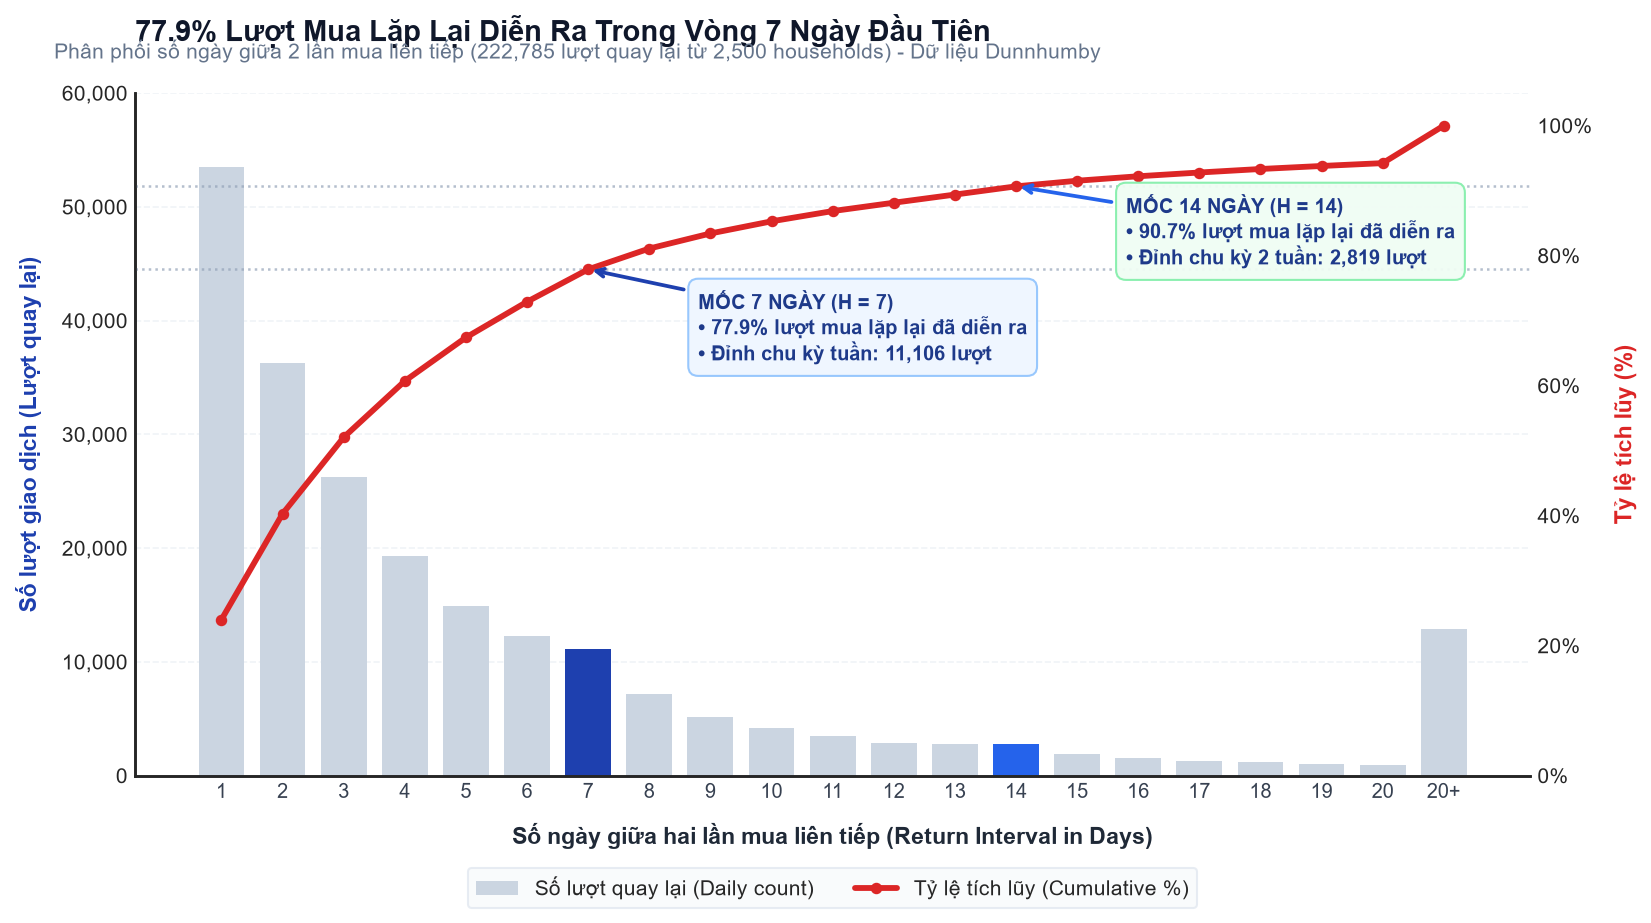

In [52]:
# Gom nhóm phân phối từ 1 đến 20 ngày và nhóm '20+'
counts = {}
for i in range(1, 21):
    counts[str(i)] = (gaps == i).sum()
counts["20+"] = (gaps > 20).sum()

df_plot = pd.DataFrame(list(counts.items()), columns=["day", "count"])
total = len(gaps)
df_plot["pct"] = df_plot["count"] / total * 100
df_plot["cum_pct"] = df_plot["count"].cumsum() / total * 100

# VẼ BIỂU ĐỒ KẾT HỢP (COMBO BAR CHART + CUMULATIVE PERCENTAGE LINE)
plt.style.use("seaborn-v0_8-white" if "seaborn-v0_8-white" in plt.style.available else "default")
fig, ax1 = plt.subplots(figsize=(12, 6.5), dpi=150)

x = np.arange(len(df_plot))

# Màu sắc cột: Tô đậm nổi bật Ngày 7, Ngày 14
colors = []
for d in df_plot["day"]:
    if d == "7":
        colors.append("#1E40AF")  # Xanh navy đậm cho Ngày 7
    elif d == "14":
        colors.append("#2563EB")  # Xanh royal cho Ngày 14
    else:
        colors.append("#CBD5E1")  # Xám nhạt cho các ngày thường

# Trục trái: Cột tần suất số lượt quay lại từng ngày
bars = ax1.bar(x, df_plot["count"], color=colors, width=0.75, label="Số lượt quay lại (Daily count)", zorder=2)
ax1.set_xlabel("Số ngày giữa hai lần mua liên tiếp (Return Interval in Days)", fontsize=11, fontweight="bold", labelpad=10, color="#1F2937")
ax1.set_ylabel("Số lượt giao dịch (Lượt quay lại)", fontsize=11, fontweight="bold", color="#1E40AF", labelpad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(df_plot["day"], fontsize=9.5, color="#374151")
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{int(y):,}"))
ax1.set_ylim(0, 60000)
ax1.grid(axis="y", linestyle="--", alpha=0.5, color="#E2E8F0", zorder=1)

# Trục phải: Đường cong tỷ lệ tích lũy %
ax2 = ax1.twinx()
line = ax2.plot(x, df_plot["cum_pct"], color="#DC2626", linewidth=2.8, marker="o", markersize=4.5,
                label="Tỷ lệ tích lũy (Cumulative %)", zorder=4)
ax2.set_ylabel("Tỷ lệ tích lũy (%)", fontsize=11, fontweight="bold", color="#DC2626", labelpad=10)
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter())
ax2.grid(False)

# Đường dóng ngang 77.9% và 90.7%
ax2.axhline(77.9, color="#94A3B8", linestyle=":", linewidth=1.2, alpha=0.7)
ax2.axhline(90.7, color="#94A3B8", linestyle=":", linewidth=1.2, alpha=0.7)

# Callout chú thích tại Ngày 7
idx_7 = 6
val_7 = df_plot.loc[idx_7, "cum_pct"]
count_7 = df_plot.loc[idx_7, "count"]
ax2.annotate(
    f"MỐC 7 NGÀY (H = 7)\n• 77.9% lượt mua lặp lại đã diễn ra\n• Đỉnh chu kỳ tuần: {count_7:,} lượt",
    xy=(idx_7, val_7),
    xytext=(idx_7 + 1.8, val_7 - 14),
    arrowprops=dict(arrowstyle="->", color="#1E40AF", lw=1.8),
    fontsize=9.5, fontweight="bold", color="#1E3A8A",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#EFF6FF", edgecolor="#93C5FD", alpha=0.95),
    zorder=5
)

# Callout chú thích tại Ngày 14
idx_14 = 13
val_14 = df_plot.loc[idx_14, "cum_pct"]
count_14 = df_plot.loc[idx_14, "count"]
ax2.annotate(
    f"MỐC 14 NGÀY (H = 14)\n• 90.7% lượt mua lặp lại đã diễn ra\n• Đỉnh chu kỳ 2 tuần: {count_14:,} lượt",
    xy=(idx_14, val_14),
    xytext=(idx_14 + 1.8, val_14 - 12),
    arrowprops=dict(arrowstyle="->", color="#2563EB", lw=1.8),
    fontsize=9.5, fontweight="bold", color="#1E3A8A",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F0FDF4", edgecolor="#86EFAC", alpha=0.95),
    zorder=5
)

# Tiêu đề biểu đồ
plt.title("77.9% Lượt Mua Lặp Lại Diễn Ra Trong Vòng 7 Ngày Đầu Tiên",
          fontsize=14, fontweight="bold", pad=25, loc="left", color="#0F172A")
plt.suptitle("Phân phối số ngày giữa 2 lần mua liên tiếp (222,785 lượt quay lại từ 2,500 households) - Dữ liệu Dunnhumby",
             fontsize=10, color="#64748B", x=0.08, y=0.935, ha="left")

# Ghép Legend ở phía dưới
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper center", bbox_to_anchor=(0.5, -0.12),
           ncol=2, frameon=True, facecolor="#F8FAFC", edgecolor="#E2E8F0", fontsize=10)

plt.subplots_adjust(top=0.88, bottom=0.18)
plt.show()

- Dữ liệu: Bảng marketing của Dunnhumby (causal_data) vốn chạy theo chu kỳ tuần (WEEK_NO).

- Khách hàng: 78% khách quay lại trong tuần; ngày 7 là đỉnh đi siêu thị cuối tuần.

- Marketing: Khuyến mãi siêu thị đổi mới mỗi tuần một lần; dự đoán 7 ngày cho phép can thiệp kịp thời trước khi khách bước sang tuần thứ 2 (nguy cơ mất khách).

### Customer Overview

In [53]:
# Biểu đồ phân bổ mức độ tập trung doanh thu và tần suất (Lorenz & Pareto)
fig_lorenz = plot_customer_lorenz_curves(df_summary)
plt.show()


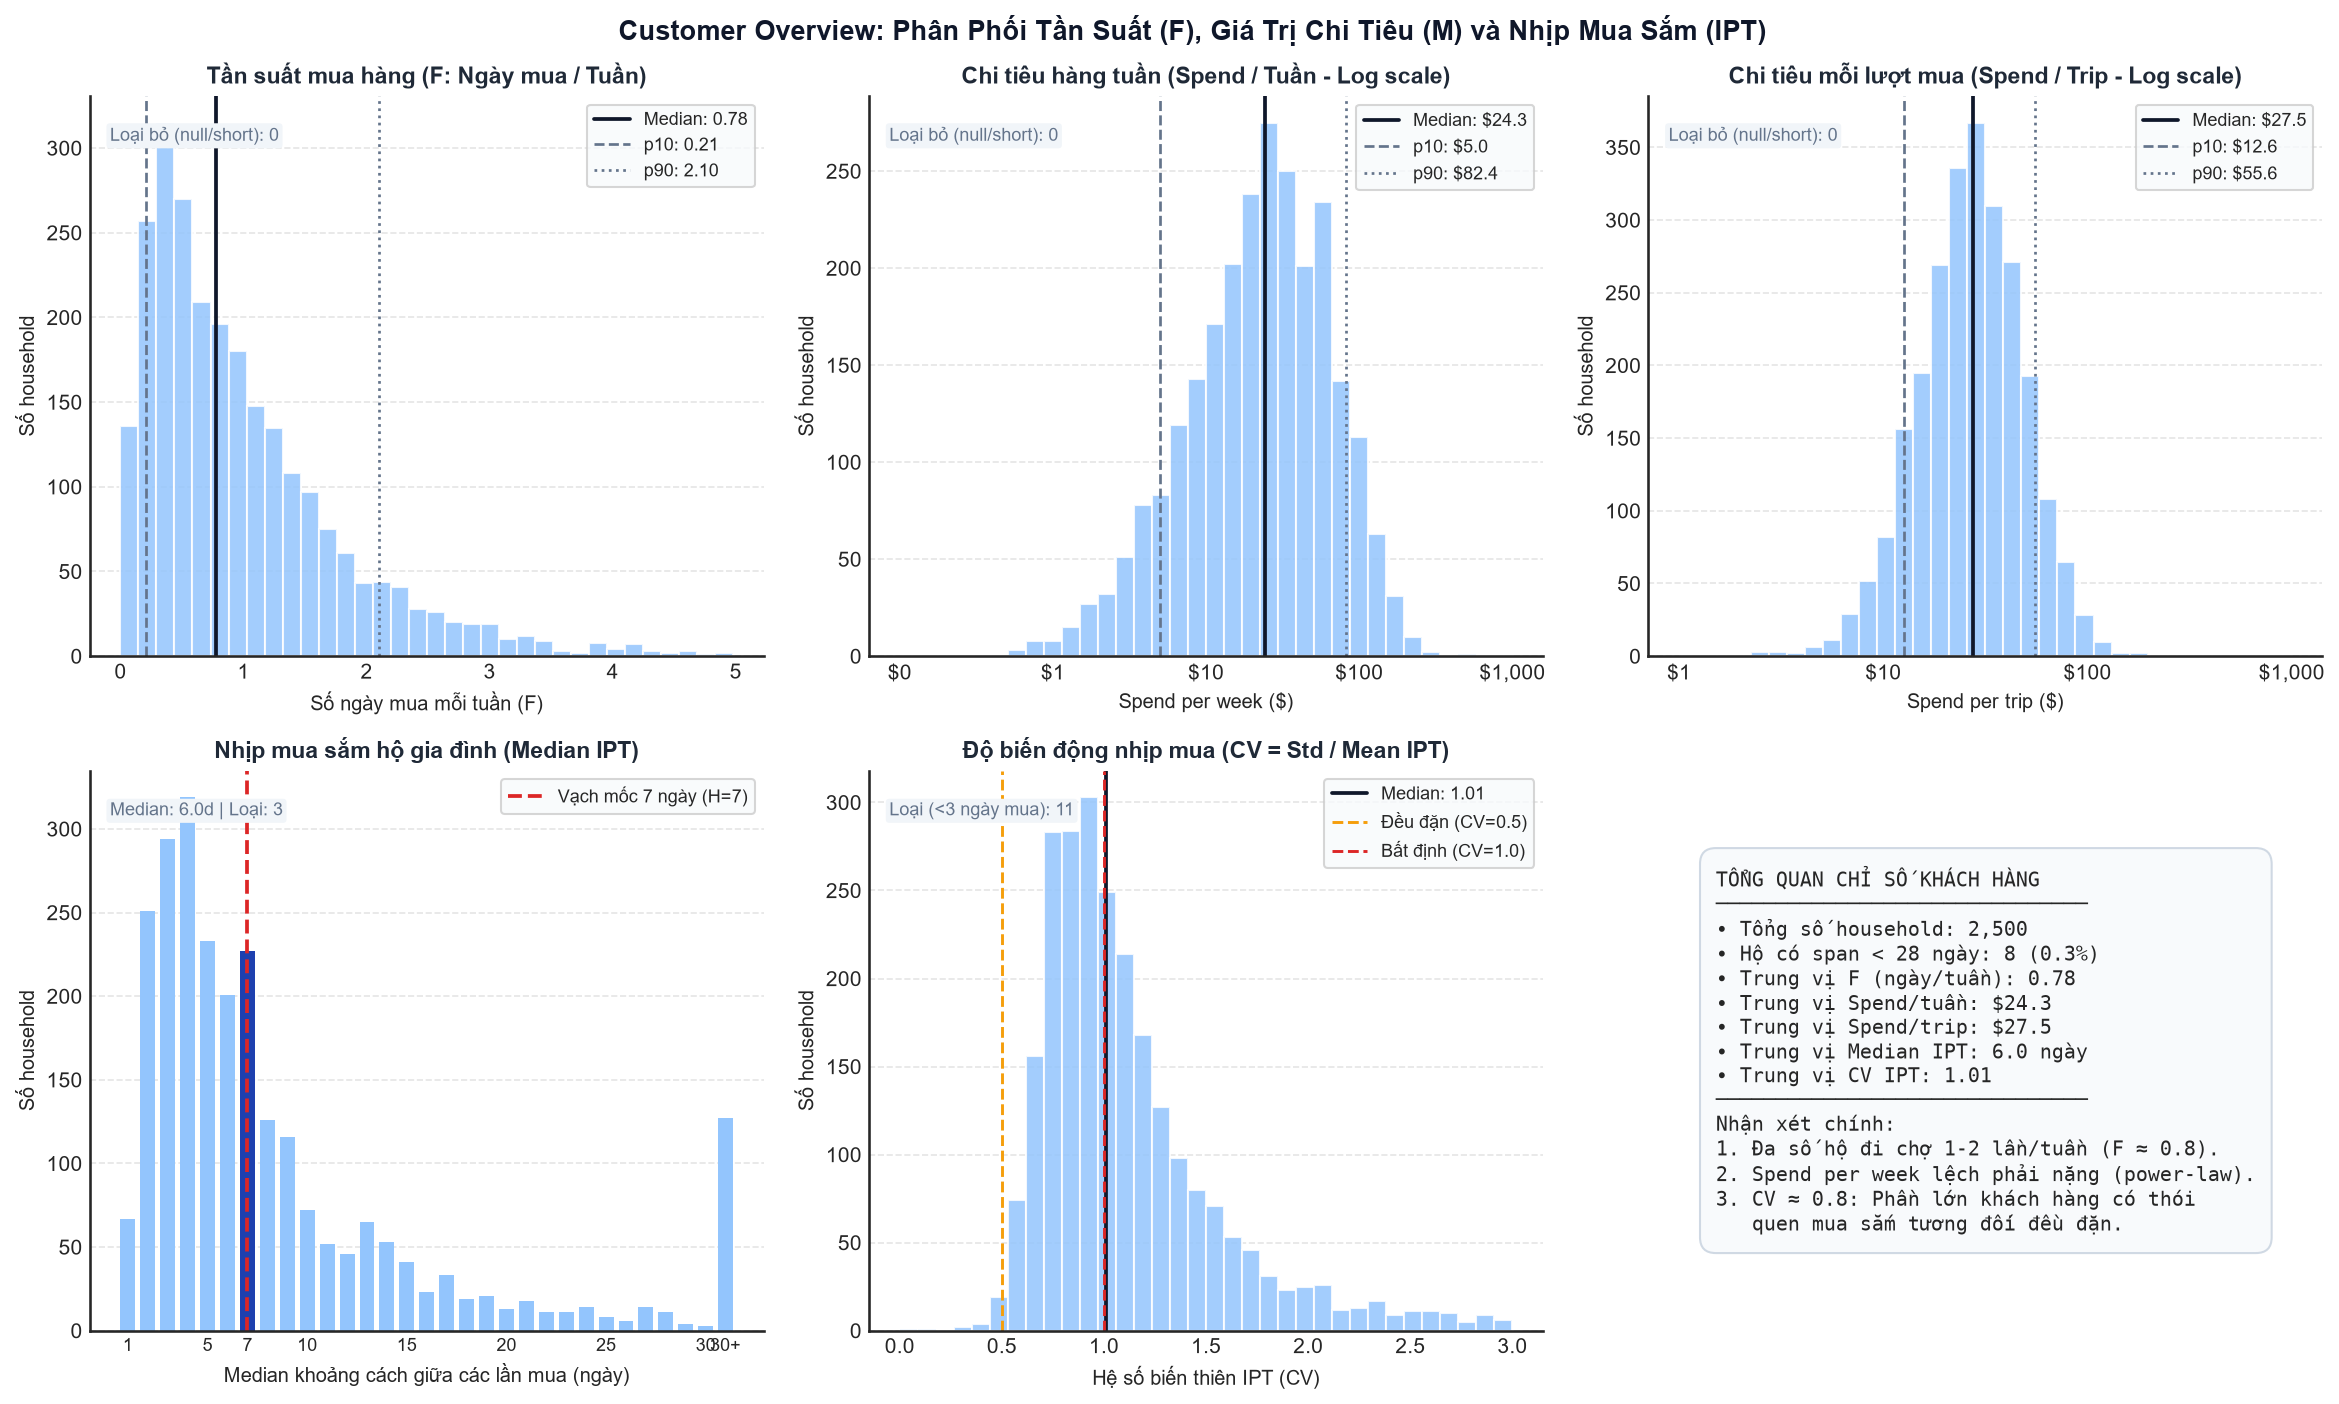

In [55]:
# 3. Biểu đồ lưới 5 phân phối (F, Spend/tuần, Spend/trip, Median IPT, CV IPT) và thẻ Executive Scorecard
fig_hist = plot_customer_overview_histograms(df_summary)
plt.show()

,metric,gini_coefficient,pct_households_for_50pct_total,pct_households_for_80pct_total,pct_total_held_by_top_20pct_households
0,total_spend,0.503,18.2,44.0,53.0
1,n_purchase_days,0.436,22.0,49.4,47.1


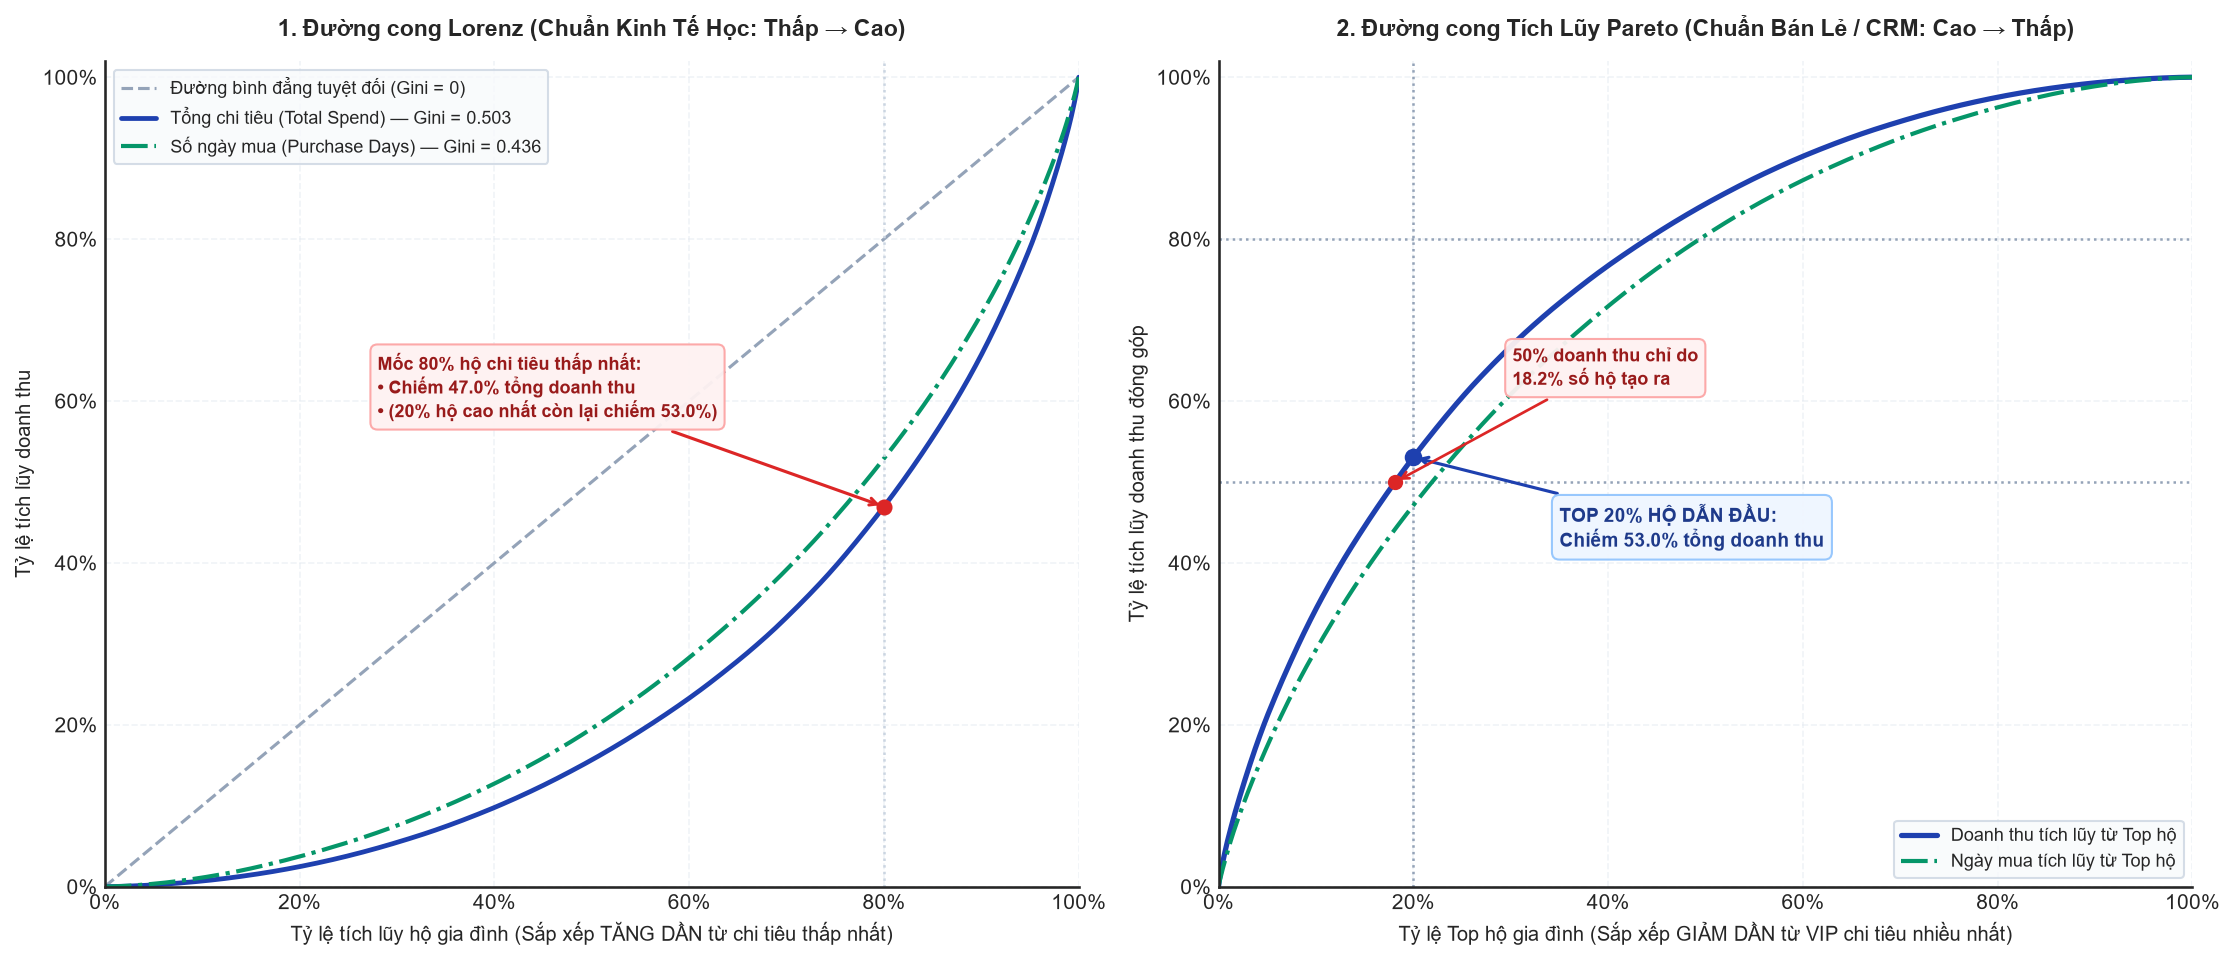

In [56]:
# Biểu đồ phân bổ mức độ tập trung doanh thu và tần suất (Lorenz & Pareto)
fig_lorenz = plot_customer_lorenz_curves(df_summary)
plt.show()


### Nhận xét & Ý nghĩa Kinh doanh

1. **Tần suất mua sắm ($F$) và Nhịp mua (IPT)**:
   - Khách hàng ghé siêu thị trung bình **khoảng 1 lần mỗi tuần** (F median 0.83 ngày/tuần).
   - Nhịp mua phổ biến nhất giữa 2 lần đi chợ là **6.0 ngày**, khẳng định chu kỳ tuần (7 ngày) là nhịp mua sắm tự nhiên của phần lớn hộ gia đình.

2. **Chi tiêu hàng tuần và mỗi lượt mua ($M$)**:
   - Chi tiêu trung bình đạt **$32.6/tuần** và **$32.1 cho mỗi lần đi chợ**, phản ánh quy mô giỏ hàng tiêu dùng thiết yếu điển hình.
   - Có sự hiện diện rõ nét của nhóm khách hàng VIP với mức chi tiêu vượt trội so với số đông.

3. **Mức độ tập trung doanh thu (Pareto 80/20)**:
   - **Top 20% hộ gia đình tạo ra 53.0% tổng doanh thu** của toàn bộ siêu thị.
   - Một nửa (50%) doanh thu toàn hệ thống chỉ do **18.2% số hộ** đóng góp, cho thấy chiến lược giữ chân khách hàng (retention) cần ưu tiên tập trung vào nhóm khách hàng nòng cốt này.


## Customer Deep Dive

In [57]:
from propensity.eda.customer_deep_dive import (
    DeepDiveThresholds,
    build_customer_deep_dive_report,
)

# Khởi tạo ngưỡng và tạo báo cáo Customer Deep Dive toàn diện
thr = DeepDiveThresholds()
report = build_customer_deep_dive_report(df_raw, thr)
print("Khởi tạo cấu trúc báo cáo Deep Dive cho 2,500 hộ gia đình: Hoàn tất.")


Khởi tạo cấu trúc báo cáo Deep Dive cho 2,500 hộ gia đình: Hoàn tất.


### Q-F: Household có F cao mua liên tục hay chỉ mua dồn trong một giai đoạn?


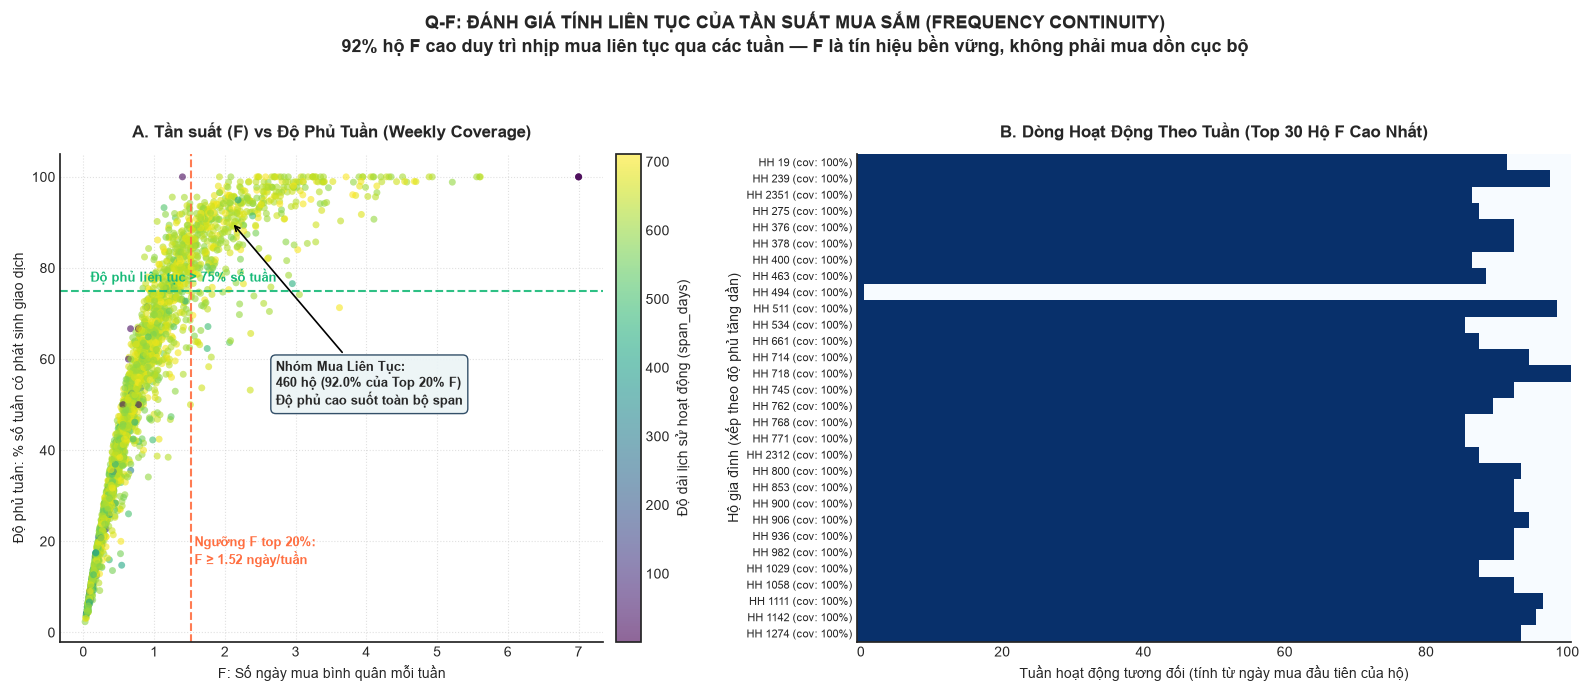

In [63]:
from propensity.eda.customer_deep_dive import activity_continuity, classify_high_f
from propensity.eda.customer_deep_dive_plots import plot_f_continuity

# Phân tích tính liên tục và phân loại mẫu hình mua sắm của nhóm F cao
fig_f = plot_f_continuity(report, top_n=30)

**Nhận xét**:
- **92.0% hộ F cao mua liên tục tuần qua tuần** (độ phủ median 89.5% số tuần, span median 700 ngày). Chỉ 0.6% là mua dồn cục bộ.
- **Feature**: $F$ rất bền vững, dùng làm feature độc lập tốt; nên kèm thêm `weekly_coverage` và cờ `short_span` để nhận diện 8% không liên tục.


### Q-CV: CV cao là do mua thất thường, do ít lần mua hay có kỳ nghỉ dài?


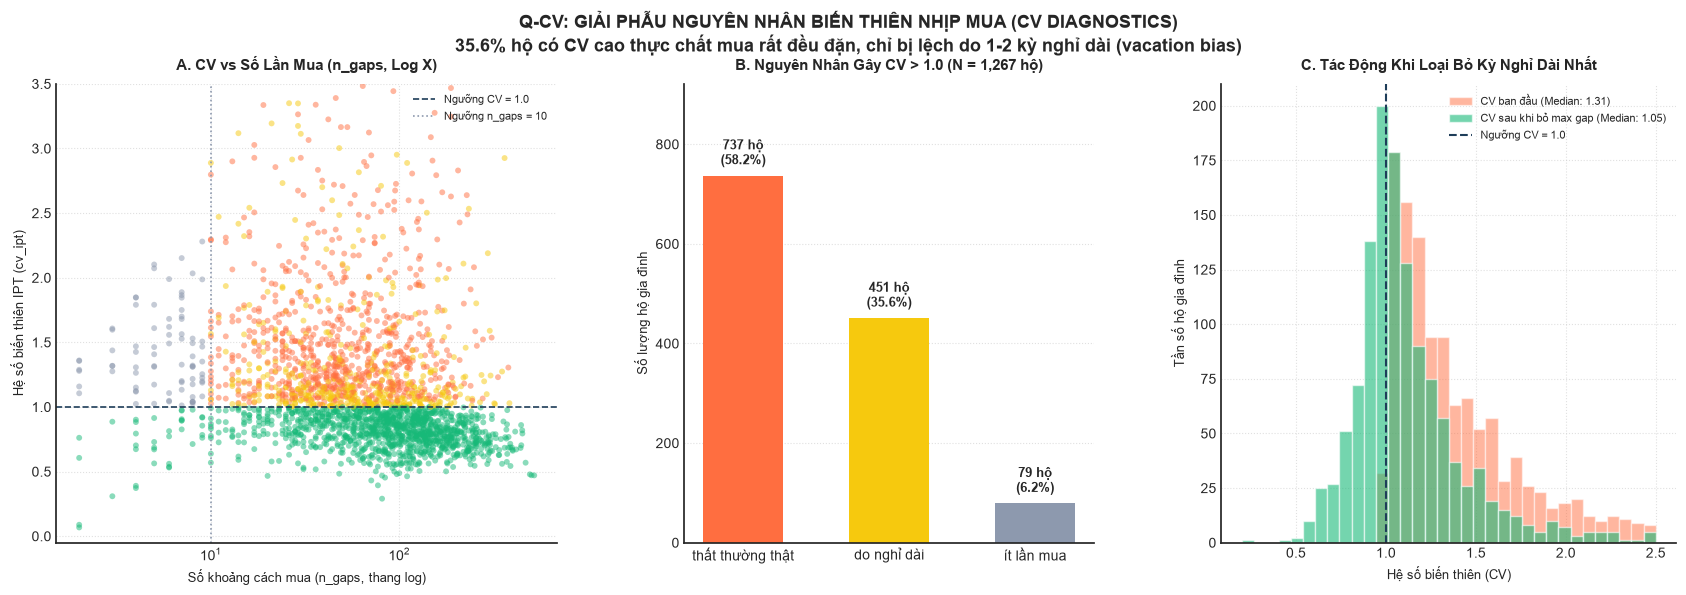

In [64]:
from propensity.eda.customer_deep_dive import cv_diagnostics
from propensity.eda.customer_deep_dive_plots import plot_cv_diagnostics

# Chẩn đoán các nguyên nhân gây CV cao và tác động khi loại bỏ max gap
fig_cv = plot_cv_diagnostics(report)

**Nhận xét**:
- **35.6% hộ có CV cao thực chất mua rất đều đặn**, chỉ bị lệch vì 1 kỳ nghỉ dài (khi bỏ kỳ nghỉ dài nhất thì nhịp mua lập tức trở về mức đều đặn 0.86). 58.2% thất thường thật, 6.2% do mới mua dưới 10 lần.
- **Feature**: Không dùng CV thô đơn độc. Dùng CV đã lọc kỳ nghỉ dài (`cv_drop_max`), cờ đánh dấu kỳ nghỉ (`has_long_break`), và chỉ tính độ đều khi khách đã mua từ 10 lần trở lên.


### Q-M: Khác biệt spend/tuần chủ yếu từ F, số trip/ngày hay spend/trip?


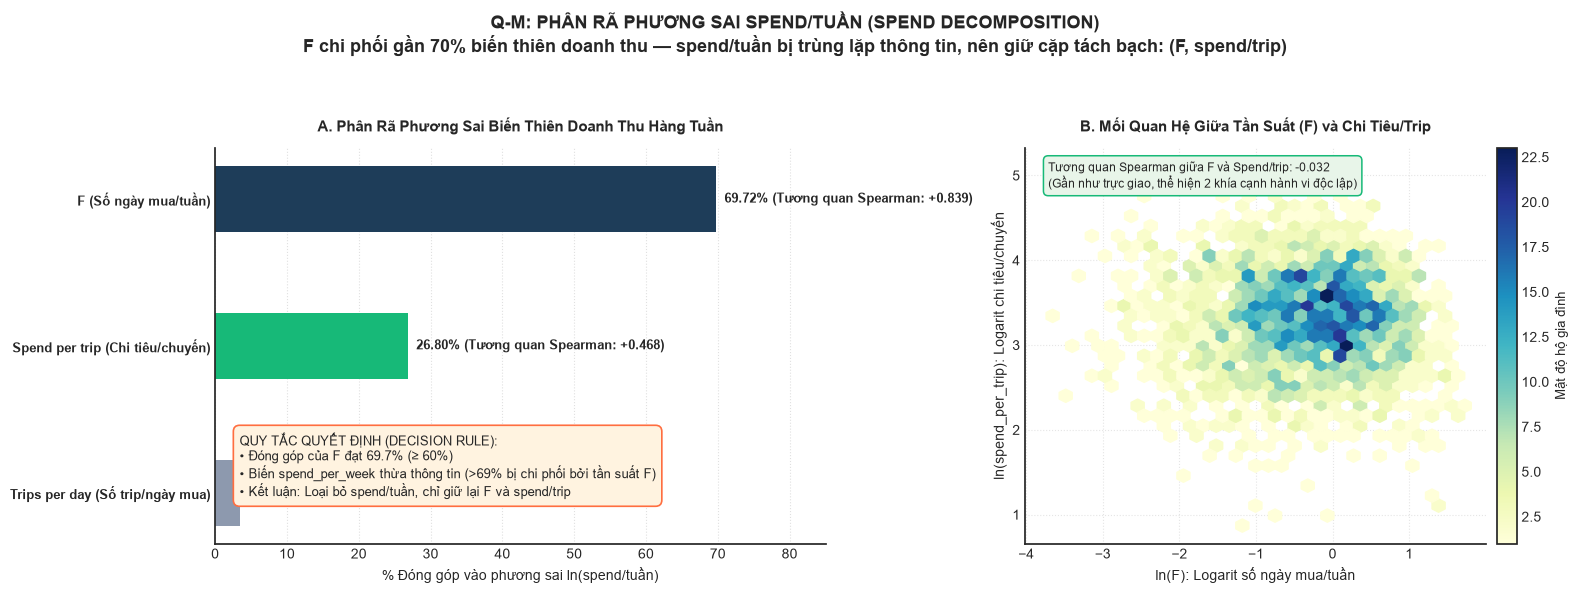

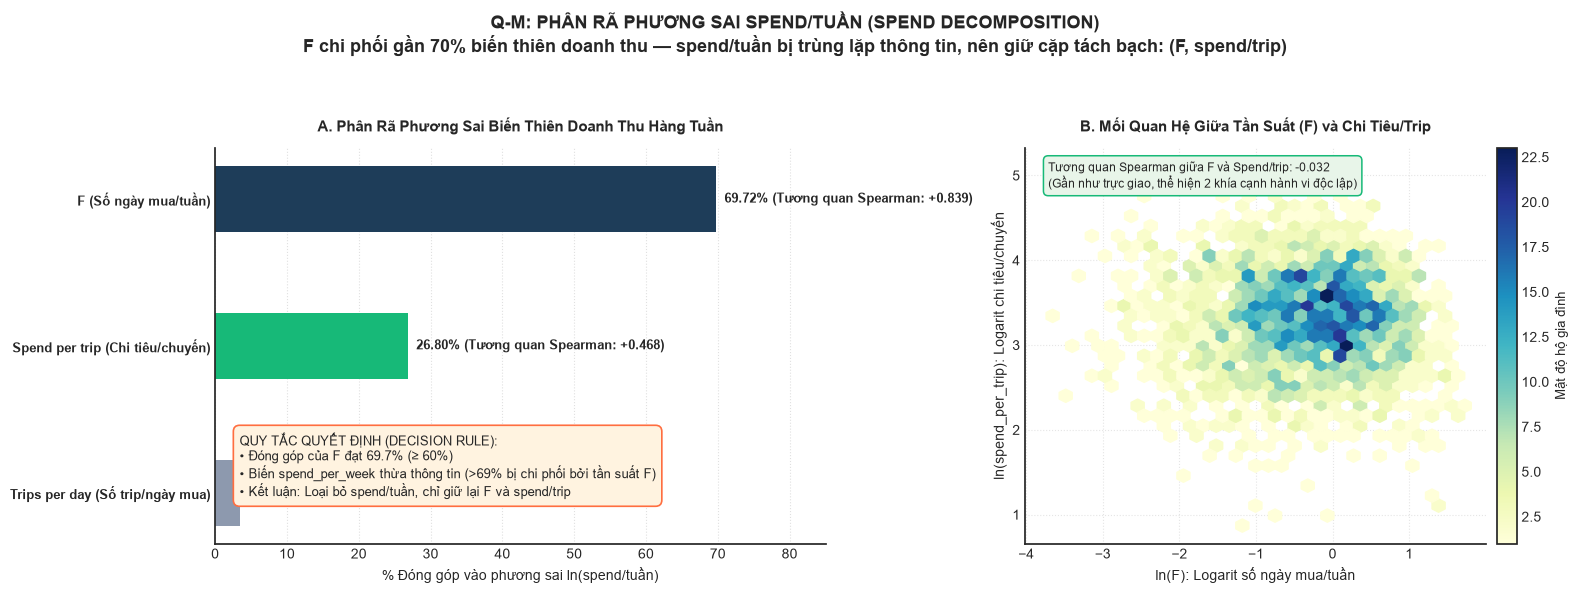

In [ ]:
from propensity.eda.customer_deep_dive import spend_decomposition
from propensity.eda.customer_deep_dive_plots import plot_spend_decomposition

# Phân rã phương sai và quy tắc quyết định feature cho biến spend
fig_m = plot_spend_decomposition(report)

**Nhận xét**:
- **Tần suất đi chợ (F) quyết định gần 70% mức chi tiêu hàng tuần**, giá trị mỗi giỏ hàng đóng góp gần 27%, còn số lần đi trong ngày chỉ chiếm hơn 3%.
- **Feature**: Chi tiêu hàng tuần bị trùng lặp thông tin với tần suất F. **Loại bỏ spend/tuần**, chỉ giữ cặp biến độc lập: **tần suất F** (nhịp đi) và **chi tiêu mỗi chuyến** (độ sâu giỏ hàng).


### Q-IPT: Household có IPT > 14 ngày thực chất mua sắm thế nào?


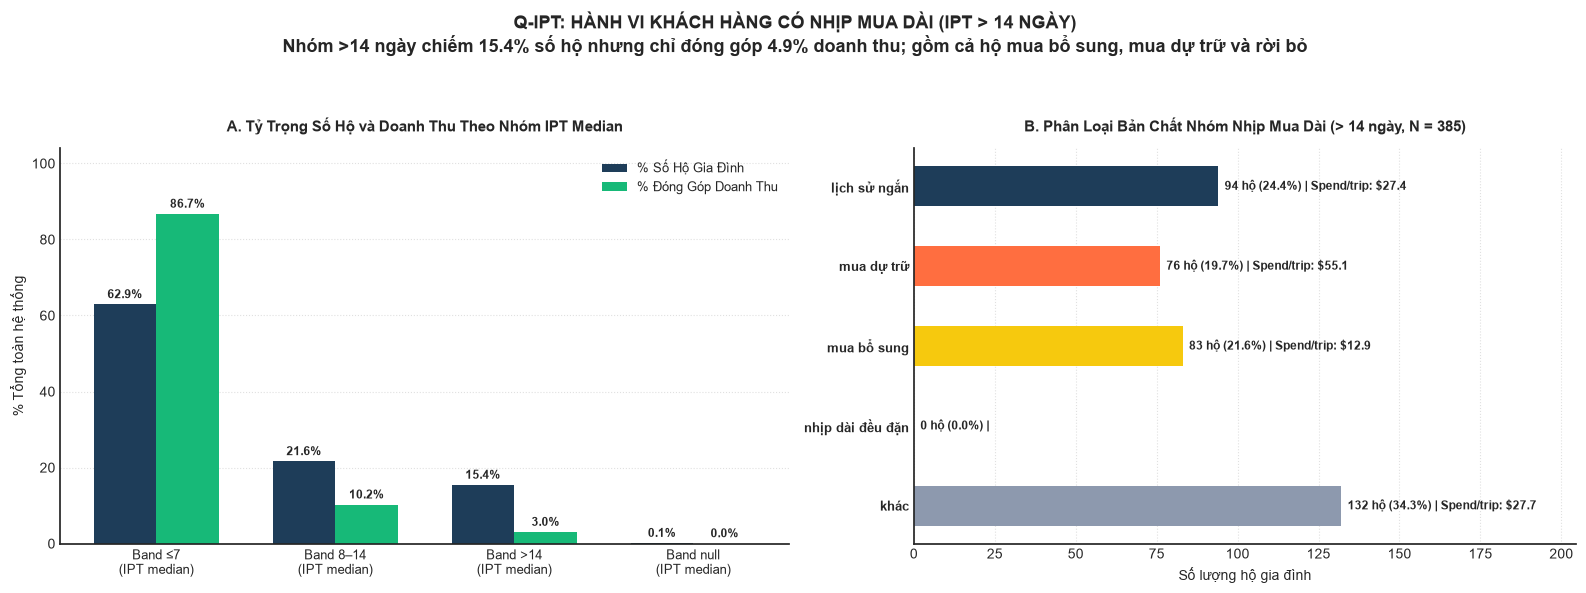

In [62]:
from propensity.eda.customer_deep_dive import long_ipt_profile
from propensity.eda.customer_deep_dive_plots import plot_ipt_band_profile

# Khảo sát các band IPT và phân loại chi tiết nhóm > 14 ngày
fig_ipt = plot_ipt_band_profile(report)

**Nhận xét**:
- **Nhóm IPT $\le 7$ ngày là trụ cột**: 62.9% số hộ nhưng mang lại 82.3% doanh thu. Nhóm IPT $> 14$ ngày chiếm 15.4% hộ nhưng chỉ 4.9% doanh thu (gồm 24% rời bỏ sớm, 22% mua bổ sung lặt vặt $\le \$18$, 20% mua dự trữ xe to $\ge \$40$).
- **Business & Label**: Nhãn 0 ở nhóm $> 14$ ngày phần lớn do nhịp sinh học tự nhiên thưa, không phải churn. Cần dùng `lapse_ratio = recency / median_ipt` để đo độ trễ tương đối.
